# Part II — Questions 6–8: k-nearest neighbours

**Working template: no solutions implemented.**

Scope: the Question 6 hypothesis visualisation, Question 7 Protocol A and explanation, and Question 8 Protocol B and explanation, following the supplied brief (Sections 2.1.1–2.1.4).


## Setup

Add the imports and random seed used below. This notebook should run independently from a fresh kernel.

The shared `knn_predict` helper below uses Euclidean distance and is available to Questions 6–8.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

### Helper Function of KNN Implementation

In [2]:
# Implementation of the KNN algorithm (In this coursework we set up k=3 or with course def v=3)
def knn_predict(centres, labels, query_point, k=3, verbose=True):
    """
    Inputs:
    - centres: A 2D numpy array of shape (n_centres, n_features) representing the coordinates of the centres.
    - labels: A 1D numpy array of shape (n_centres,) representing the labels associated with each centre.
    - query_point: A 1D numpy array of shape (n_features,) representing the coordinates of the query point.
    - k: An integer representing the number of nearest neighbours to consider (default is 3).
    - verbose: A boolean indicating whether to print debug information (default is True).
    
    Output:
    - The predicted label for the query point based on the majority vote of the k nearest neighbours
    """
    
    # Calculate the Euclidean distances from the query point to all centres
    # Using numpy's broadcasting and vectorization to compute distances efficiently
    distances = np.linalg.norm(centres - query_point, axis=1) # 'axis=1' computes the norm along rows
                                                                        # (i.e., for each centre)
    if verbose:
        print(f"Distances from query point {query_point} to centres: {distances}")
    
    # Get the indices of the k nearest neighbours
    nearest_indices = np.argsort(distances)[:k] 
    if verbose:
        print(f"Indices of the {k} nearest neighbours: {nearest_indices}")

    # Get the labels of the k nearest neighbours
    nearest_labels = labels[nearest_indices]
    if verbose:
        print(f"Labels of the {k} nearest neighbours: {nearest_labels}")

    # Get the most common label among the nearest neighbours without numpy's bincount
    vote = {}
    for label in nearest_labels:
        if label in vote:
            vote[label] += 1
        else:
            vote[label] = 1
    if verbose:
        print(f"Votes for each label: {vote}")

    return max(vote, key=vote.get)  # Return the label with the highest vote

## Question 6 — Generate and evaluate a voted-centre hypothesis

Sample 100 centres independently and uniformly from [0,1]^2, with independent labels sampled uniformly from {0,1}. Set v=3.

Define h(x) as the majority label among the three nearest centres. This nearest-centre calculation is needed to colour the plot in Question 6. Resolve undefined results by sampling a label uniformly from {0,1}, as required by Section 2.1.4. State the distance used.


In [3]:
# Step 1: Sample 5 centres, each with two independent uniform coordinates.
# First parameter is the lower bound (inclusive), second parameter is the upper bound (exclusive),
# Third parameter is the size of the output array that we want,
# in this case 5 rows of two columns each one,
# i.e. 5 centres in 2D space or 5 tuples.
centres = np.random.uniform(0, 1, size=(5, 2)) 

# Step 2: Sample 5 independent, equally likely binary labels for each centre.
# First parameter is the lower bound (inclusive), the second parameter is the upper bound (exclusive),
# Third parameter is the size of the output array that we want,
# in this case 5 rows, of one column each one, i.e. 5 labels.
labels = np.random.randint(0, 2, size=5) 

# labels[i] is the label associated with centres[i].

for i in range(5):
    # First 5 examples to see all is correct.
    print(f"Centre: {centres[i]}, Label: {labels[i]}")


Centre: [0.47678398 0.47169838], Label: 1
Centre: [0.94829089 0.22685993], Label: 1
Centre: [0.27225443 0.13547262], Label: 0
Centre: [0.030225   0.55955398], Label: 0
Centre: [0.60926176 0.88492956], Label: 0


In [4]:
# Toy example to test the shared KNN implementation
query_point = np.array([0.7, 0.65])
k = 3
predicted_label = knn_predict(centres, labels, query_point, k)
print(f"Predicted label for query point {query_point} with k={k}: {predicted_label}")

Distances from query point [0.7  0.65] to centres: [0.28568665 0.49060767 0.66910739 0.6758543  0.25184386]
Indices of the 3 nearest neighbours: [4 0 1]
Labels of the 3 nearest neighbours: [0 1 1]
Votes for each label: {np.int64(0): 1, np.int64(1): 2}
Predicted label for query point [0.7  0.65] with k=3: 1


### Question 6 — Plot the hypothesis

Produce a visualisation of h similar to Figure 1: evaluate h on a grid over [0,1]^2, colour the regions for labels 0 and 1, and superimpose the 100 labelled centres. Use distinguishable colours and equal axis scaling.


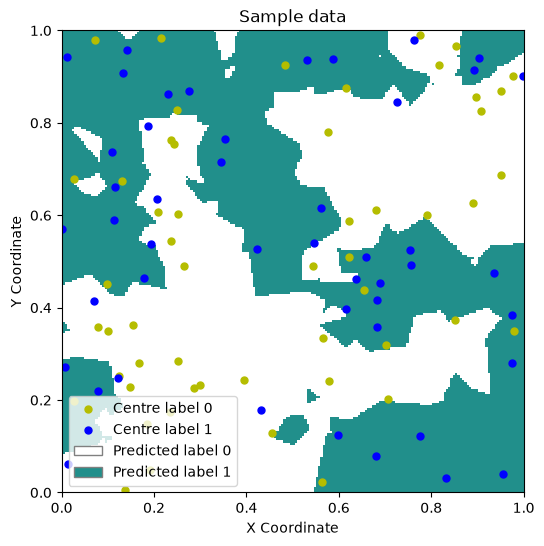

In [5]:
from matplotlib.patches import Patch

# 0. Create a 100 x 2 array of centres and a 1D array of 100 labels.
centres = np.random.uniform(0, 1, size=(100, 2))
labels = np.random.randint(0, 2, size=100)

# 1. Create a 200 x 200 grid over [0, 1]^2.
temporal_grid = np.linspace(0, 1, 200) # first param is the lower bound, second param is the upper bound,
                                       # third param is the number of points
                                       # Both endpoints are included; shape is (200,).
# For example if we had temporal_grid = np.linspace(0, 1, 3), we would get the following array:
# array([0. , 0.5, 1. ])
                                       
xx, yy = np.meshgrid(temporal_grid, temporal_grid) # first param is the x-coordinates, second param is the
                                               # y-coordinates
# Continuing the example, np.meshgrid(temporal_grid, temporal_grid) would give us the following two 2D arrays:
# xx = array([[0. , 0.5, 1.  ],
#              [0. , 0.5, 1.  ],
#              [0. , 0.5, 1.  ]])
# yy = array([[0. , 0. , 0.  ],
#              [0.5, 0.5, 0.5],
#              [1. , 1. , 1.  ]])
   
grid_points = np.column_stack((xx.ravel(), yy.ravel())) # .ravel() flattens the 2D arrays into 1D arrays,
                                                      # and np.column_stack combines them into a 2D array of shape (40000, 2).
# Following the example, .ravel() would give us:
# xx.ravel() = array([0. , 0.5, 1. , 0. , 0.5, 1. , 0. , 0.5, 1. ])
# yy.ravel() = array([0. , 0. , 0. , 0.5, 0.5, 0.5, 1. , 1. , 1. ])
# And np.column_stack would give us:
# grid_points = array([[0. , 0. ],
#                      [0.5, 0. ],
#                      [1. , 0. ],
#                      [0. , 0.5],
#                      [0.5, 0.5],
#                      [1. , 0.5],
#                      [0. , 1. ],
#                      [0.5, 1. ],
#                      [1. , 1. ]])

# 2. Predict each grid point using the three nearest centres.
predictions = []
for point in grid_points:
    # Silence debug output while evaluating all 40,000 grid points.
    predicted_label = knn_predict(centres, labels, point, 3, verbose=False)
    predictions.append(predicted_label)

# 3. Arrange the predictions to match the grid.
# Previously, we flattened the grid into a 1D array to make predictions. 
# Now, we need to reshape the predictions back into a 2D array of shape (200, 200) to match the original grid shape.
# For our example, prediction_grid would look like this:
# prediction_grid = array([[0, 0, 1],
#                          [0, 1, 1],
#                          [1, 1, 1]]) 
# Assuming the predictions were made in the order of the flattened grid points.
prediction_grid = np.array(predictions).reshape(xx.shape)

# 4. Draw the background: white for 0, turquoise for 1.
background_colours = ListedColormap(["white", "#218f8b"])
plt.figure(figsize=(6, 6))
plt.pcolormesh(
    xx, yy, prediction_grid,
    cmap=background_colours,
    vmin=0,
    vmax=1,
    shading="nearest"
)

# 5. Draw the labelled centres on top of the prediction regions.
plt.scatter(
    centres[labels == 0, 0], centres[labels == 0, 1],
    color="#b5bd00", label="Centre label 0", s=25
)
plt.scatter(
    centres[labels == 1, 0], centres[labels == 1, 1],
    color="blue", label="Centre label 1", s=25
)
plt.title("Sample data")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.gca().set_aspect("equal")
# Explain both the centre markers and the background prediction colours.
handles, _ = plt.gca().get_legend_handles_labels()
handles.extend([
    Patch(facecolor=background_colours(0), edgecolor="grey", label="Predicted label 0"),
    Patch(facecolor=background_colours(1), edgecolor="grey", label="Predicted label 1"),
])
plt.legend(handles=handles)
plt.show()


## Questions 7–8 — Noisy data and k-NN

Reuse the shared `knn_predict` helper defined after the imports for the experiments below. Resolve undefined predictions, including tied binary votes, uniformly at random as required by Section 2.1.4.

For a given h, sample each input x uniformly from [0,1]^2. With probability 0.8 use y=h(x); otherwise sample y uniformly from {0,1}. Generate both training and test examples this way. The 0.2 branch samples a fresh random label, so it can agree with h(x); it does not always flip the label.


## Question 7(a) — Protocol A

Follow Figure 2 with this loop order:

```text
for each k in {1,...,49}:
    for each of 100 runs:
        sample a fresh hypothesis h
        sample 4000 training examples from p_h(x,y)
        sample 1000 independent test examples from p_h(x,y)
        predict the test labels using k-NN on the training examples
        record the fraction of incorrect test predictions
    average the 100 run errors for this k
```

Plot k on the horizontal axis and its mean estimated generalisation error on the vertical axis.


## Question 7(b) — Explain the observed curve

In roughly five sentences, explain the approximate shape of the resulting figure and comment on any interesting features.


## Question 8(a) — Protocol B

Follow Figure 3 with this loop order:

```text
for each m in {100,500,1000,1500,2000,2500,3000,3500,4000}:
    for each of 100 runs:
        for each k in {1,...,49}:
            sample a fresh hypothesis h
            sample m training examples from p_h(x,y)
            sample 1000 independent test examples from p_h(x,y)
            record the k-NN test error
        select the k with the smallest error in this run
    average the 100 selected k values for this m
```

Plot m on the horizontal axis and the mean selected k on the vertical axis. Record how equally minimal errors are handled. The hypothesis and data are sampled inside the k loop, as shown in Figure 3. Average the run-level selected k values; do not select k by minimising an error curve averaged across runs.


## Question 8(b) — Explain the observed relationship

In roughly four sentences, explain the approximate shape of the resulting figure relating m to the estimated optimal k.
